# 01 — Curva epidemiológica e sinais de alerta

Vamos transformar notificações semanais em uma leitura temporal, usando média móvel e um limiar didático.

In [ ]:
from pathlib import Path
import sys, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
ROOT=Path.cwd().parent if Path.cwd().name=="notebooks" else Path.cwd()
sys.path.insert(0,str(ROOT))
from scripts.carregar_dados import caminhos, semana_epidemiologica
arq_casos, _, FONTE = caminhos()

# 1. Carregando os dados e preparando as curvas epidemiológicas para Itumbiara
casos={ano:pd.read_csv(p,parse_dates=["semana"]) for ano,p in arq_casos.items()}
print("Fonte selecionada:",FONTE,"| anos:",", ".join(casos))
curvas,limiares={},{}
for ano,df in casos.items():
    # Filtrando os casos de Itumbiara e ordenando por semana
    it=df.query("municipio == 'Itumbiara'").sort_values("semana").copy()
    if it.empty: raise ValueError(f"Itumbiara não foi encontrada na base de {ano}.")
    it["semana_epi"]=semana_epidemiologica(it.semana)[1]
    it["media_4s"]=it.casos.rolling(4,min_periods=1).mean()
    # Calculando a linha de base com os primeiros 10 registros ou menos, se houver menos de 10 semanas
    baseline=it.casos.iloc[:min(10,len(it))]

    # Definindo o limiar de alerta como a média da linha de base mais duas vezes o desvio padrão
    limiares[ano]=baseline.mean()+2*baseline.std()
    # Marcando as semanas em que a média móvel ultrapassa o limiar de alerta
    it["alerta"]=it.media_4s>limiares[ano]
    curvas[ano]=it
    # Exibindo as últimas semanas processadas para conferência
    display(it.tail())

Fonte selecionada: SINAN/DATASUS + IBGE (dados oficiais agregados) | anos: 2024, 2025


,codigo_ibge,municipio,semana,casos,semana_epi,media_4s,alerta
3857,5211503.0,Itumbiara,2024-11-17,3,47,1.75,False
3858,5211503.0,Itumbiara,2024-11-24,5,48,2.75,False
3859,5211503.0,Itumbiara,2024-12-01,3,49,3.00,False
3860,5211503.0,Itumbiara,2024-12-08,3,50,3.50,False
3861,5211503.0,Itumbiara,2024-12-15,2,51,3.25,False


,codigo_ibge,municipio,semana,casos,semana_epi,media_4s,alerta
3276,5211503,Itumbiara,2025-11-30,12,49,19.25,True
3277,5211503,Itumbiara,2025-12-07,24,50,23.25,True
3278,5211503,Itumbiara,2025-12-14,39,51,30.00,True
3279,5211503,Itumbiara,2025-12-21,34,52,27.25,True
3280,5211503,Itumbiara,2025-12-28,44,53,35.25,True


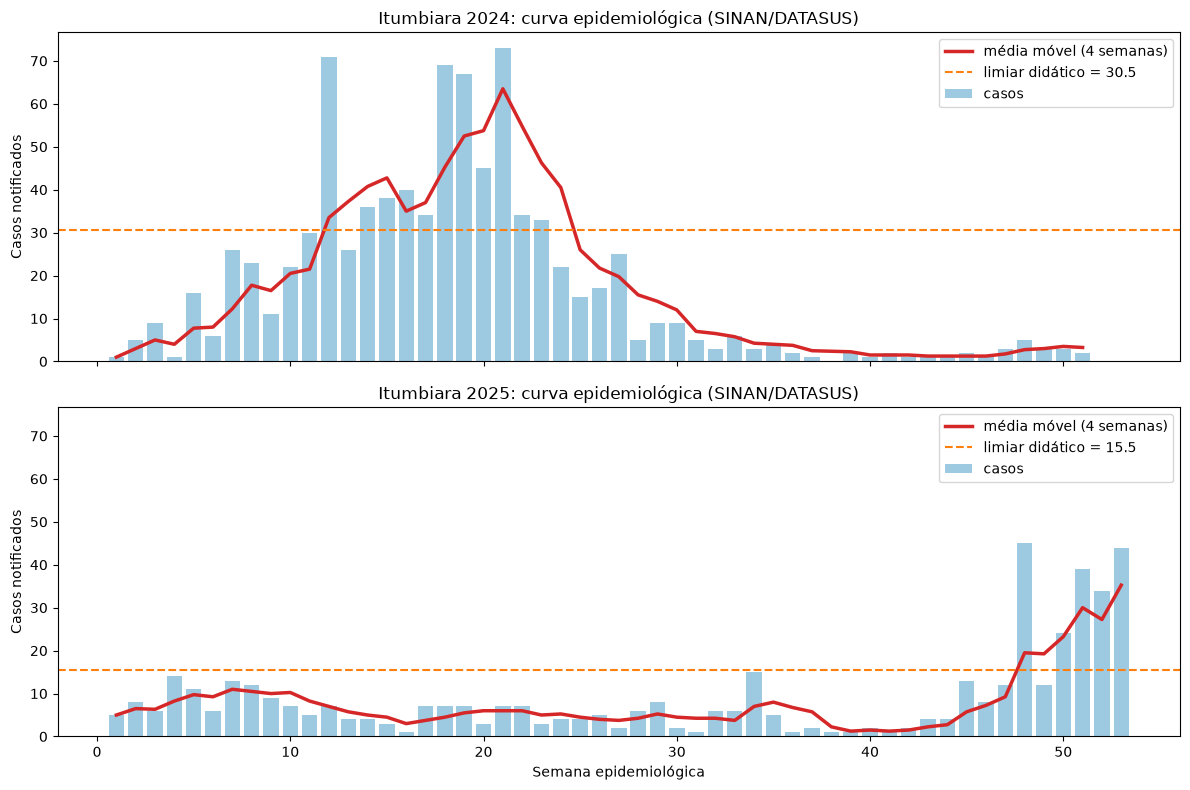

In [ ]:
# Um painel por ano, mesmo eixo de semanas epidemiológicas e mesma escala: compare quando o surto começa e atinge o pico
fig,axes=plt.subplots(len(curvas),1,figsize=(12,4*len(curvas)),sharex=True,sharey=True,squeeze=False)

# 2. Plotando as curvas epidemiológicas de Itumbiara, um painel por ano
for ax,(ano,it) in zip(axes[:,0],curvas.items()):
    # Preparando os dados para o ano atual
    ax.bar(it.semana_epi,it.casos,width=0.8,color="#9ecae1",label="casos")
    ax.plot(it.semana_epi,it.media_4s,color="#d62728",lw=2.5,label="média móvel (4 semanas)")
    ax.axhline(limiares[ano],color="#ff7f0e",ls="--",label=f"limiar didático = {limiares[ano]:.1f}")
    ax.set(title=f"Itumbiara {ano}: curva epidemiológica (SINAN/DATASUS)",ylabel="Casos notificados")
    ax.legend()
axes[-1,0].set_xlabel("Semana epidemiológica")
plt.tight_layout(); plt.show()

In [3]:

# 3. Exibindo as primeiras semanas de alerta para conferência
# Apenas as semanas em que o alerta foi acionado, limitando a 10 registros por ano
pd.concat({ano:it.loc[it.alerta,["semana","semana_epi","casos","media_4s"]].head(10) for ano,it in curvas.items()})

semana  semana_epi  casos  media_4s
2024 3823 2024-03-17          12     71     33.50
     3824 2024-03-24          13     26     37.25
     3825 2024-03-31          14     36     40.75
     3826 2024-04-07          15     38     42.75
     3827 2024-04-14          16     40     35.00
     3828 2024-04-21          17     34     37.00
     3829 2024-04-28          18     69     45.25
     3830 2024-05-05          19     67     52.50
     3831 2024-05-12          20     45     53.75
     3832 2024-05-19          21     73     63.50
2025 3275 2025-11-23          48     45     19.50
     3276 2025-11-30          49     12     19.25
     3277 2025-12-07          50     24     23.25
     3278 2025-12-14          51     39     30.00
     3279 2025-12-21          52     34     27.25
     3280 2025-12-28          53     44     35.25

### Cuidado de interpretação

Dados do limiar acima é pedagógico: Acima de Média + 2x STD

A análise real deve considerar atraso de notificação, sazonalidade, definição de caso, população exposta e protocolos epidemiológicos.